# 01 — Datos: TinyHero

Este notebook documenta **origen, licencia, tamaño y preparación** de los datos (requisito 1 del proyecto).
Todo lo que se hace aquí está implementado en `src/data.py`; el notebook solo lo ejecuta y lo muestra.

In [1]:
import os, sys
# Si se ejecuta desde notebooks/, subir a la raíz del repo para que `src` y `data/` se encuentren.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import json
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from src.data import TinyHero, VIEW_NAMES, DATA_URL
from src.utils import grid_image

## Origen

- **Dataset:** *TinyHero*, del proyecto "Tiny Hero – Generating pixel characters with GANs" de Agnieszka Mikołajczyk.
  El enlace original (amikolajczyk.netlify.com) ya no funciona; el archivo `data.zip` se descarga del repositorio de la autora:
  https://github.com/AgaMiko/pixel_character_generator
- **Cómo se creó:** los personajes se generaron aleatoriamente (sexo, tipo de cuerpo, tono de piel, equipo) con el
  *Universal LPC Spritesheet Character Generator* de makrohn, que combina el arte del **Liberated Pixel Cup (LPC)**.
- **Contenido:** sprites de pixel art estilo RPG de 16 bits. No hay rostros de personas reales ni personajes con copyright.

## Licencia

El arte LPC tiene **doble licencia: CC-BY-SA 3.0 y GNU GPL 3.0**. Ambas exigen **atribución** (LPC contributors,
makrohn, A. Mikołajczyk) y **compartir bajo la misma licencia**, así que los pesos y la galería que publiquemos
quedan bajo esas mismas licencias.

In [2]:
ds = TinyHero("data", hflip=False)   # descarga y descomprime si hace falta
print("Fuente:", DATA_URL)
print("Imágenes:", len(ds), "| tensor:", tuple(ds.images.shape), ds.images.dtype)

Fuente: https://github.com/AgaMiko/pixel_character_generator/raw/master/data.zip
Imágenes: 3648 | tensor: (3648, 3, 64, 64) torch.uint8


## Tamaño

3 648 imágenes de 64×64, repartidas en 4 carpetas (una por vista). El orden de las carpetas es el de las filas
de la hoja de sprites LPC: arriba (espalda), izquierda, abajo (frente), derecha.

In [3]:
counts = torch.bincount(ds.views, minlength=4).tolist()
for v, n in enumerate(counts):
    print(f"carpeta {v} = {VIEW_NAMES[v]:9s}: {n} imágenes")

carpeta 0 = espalda  : 912 imágenes
carpeta 1 = izquierda: 912 imágenes
carpeta 2 = frente   : 912 imágenes
carpeta 3 = derecha  : 912 imágenes


**Observación importante:** el archivo `k.png` es **el mismo personaje** en las 4 carpetas. O sea, el dataset
son **912 personajes únicos × 4 vistas**. Esto importa al analizar novedad y vecinos más cercanos: un vecino
"casi idéntico" puede ser otra vista del mismo personaje, no necesariamente memorización.
La figura muestra los primeros 8 personajes (columnas) en las 4 vistas (filas):

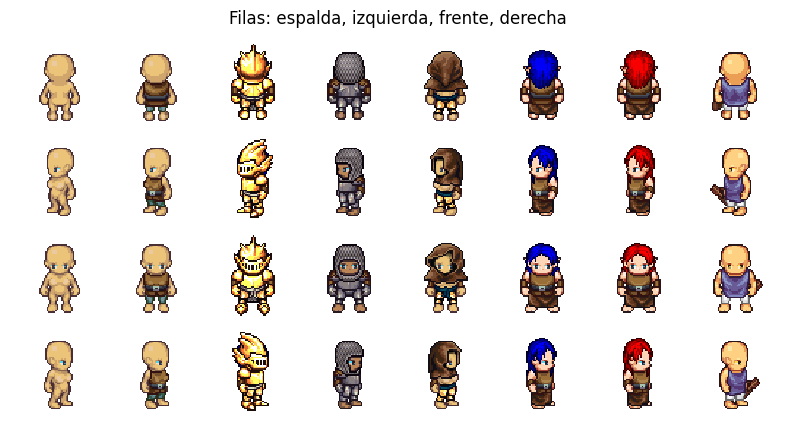

In [4]:
per_view = torch.stack([ds[int(i)][0] for v in range(4) for i in torch.nonzero(ds.views == v).flatten()[:8]])
plt.figure(figsize=(10, 5.5))
plt.imshow(grid_image(per_view, nrow=8, scale=3), interpolation="nearest")
plt.axis("off"); plt.title("Filas: espalda, izquierda, frente, derecha"); plt.show()

## Preparación

| Paso | Decisión | Por qué |
|---|---|---|
| Canal alfa | Los PNG son RGBA; se **componen sobre fondo blanco** y se pasan a RGB | La GAN genera 3 canales; un fondo fijo evita que tenga que aprender transparencia. Blanco hace legibles los contornos oscuros. |
| Resolución | Se verificó que **todas son 64×64** (no hubo que redimensionar) | Si hiciera falta, se usaría `NEAREST`: el bilineal emborrona el pixel art. |
| Normalización | **[−1, 1]** con `x / 127.5 − 1` | El generador termina en `tanh`, cuyo rango es [−1, 1]. |
| Aumento | **Flip horizontal, p = 0.5** (solo en entrenamiento) | Válido en el modelo incondicional: un sprite volteado sigue siendo plausible. Si se condicionara por vista, el flip mezclaría izquierda/derecha y habría que quitarlo. |
| Batches | `drop_last=True` con batch 128 → 28 iteraciones/época | 3 648 = 28·128 + 64; un batch final más chico altera las estadísticas de BatchNorm. |

In [5]:
from PIL import Image as _I
import glob
sizes = {(_I.open(f).size, _I.open(f).mode) for f in glob.glob("data/tinyhero/data/*/*.png")}
print("Tamaños y modos encontrados en los PNG:", sizes)
x, _ = ds[0]
print("Tras la preparación:", tuple(x.shape), x.dtype, f"rango [{x.min():.0f}, {x.max():.0f}]")

Tamaños y modos encontrados en los PNG: {((64, 64), 'RGBA')}
Tras la preparación: (3, 64, 64) torch.float32 rango [-1, 1]


## Muestra real: 64 imágenes al azar (semilla 0)

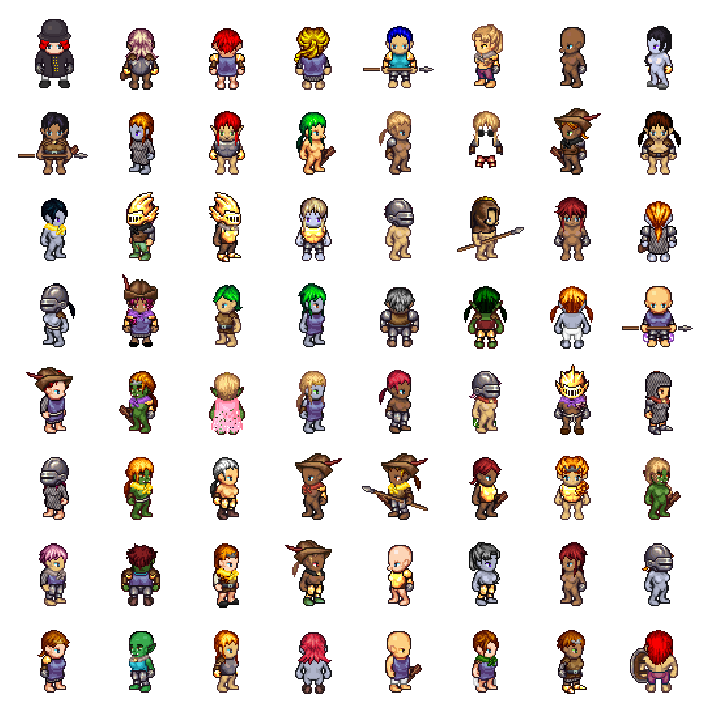

In [6]:
g = torch.Generator().manual_seed(0)
idx = torch.randperm(len(ds), generator=g)[:64]
plt.figure(figsize=(9, 9))
plt.imshow(grid_image(torch.stack([ds[i][0] for i in idx]), nrow=8, scale=3), interpolation="nearest")
plt.axis("off"); plt.show()

## Paleta: colores distintos por imagen

El pixel art usa paletas pequeñas. Contar colores únicos por imagen da una idea de qué tan "limpia" tiene que ser
una muestra generada para parecer pixel art (una GAN tiende a producir muchos colores intermedios).

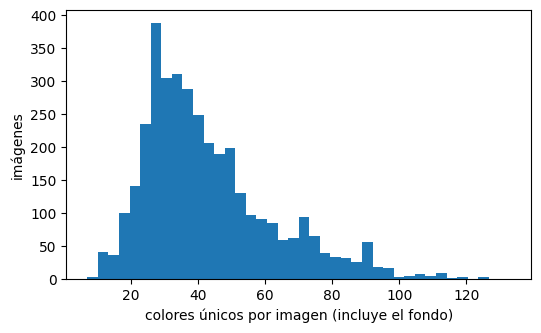

mediana 38, min 7, max 133


In [7]:
uniq = [len(np.unique(ds.images[i].reshape(3, -1).T.numpy(), axis=0)) for i in range(len(ds))]
plt.figure(figsize=(6, 3.5))
plt.hist(uniq, bins=40)
plt.xlabel("colores únicos por imagen (incluye el fondo)"); plt.ylabel("imágenes"); plt.show()
print(f"mediana {np.median(uniq):.0f}, min {min(uniq)}, max {max(uniq)}")

In [8]:
# Estadísticas que quedan guardadas para el informe (las genera `python -m src.data`).
print(open("outputs/data_stats.json", encoding="utf-8").read())

{
  "n_images": 3648,
  "n_per_view": {
    "espalda": 912,
    "izquierda": 912,
    "frente": 912,
    "derecha": 912
  },
  "resolution": [
    64,
    64
  ],
  "channels": "RGB (PNG RGBA compuesto sobre fondo blanco)",
  "normalization": "[-1, 1]  (x / 127.5 - 1), coincide con la salida tanh de G",
  "augmentations": [
    "RandomHorizontalFlip(p=0.5) (solo en entrenamiento)"
  ],
  "resize": "ninguno necesario (todas son 64x64); si hiciera falta: NEAREST",
  "source": "https://github.com/AgaMiko/pixel_character_generator/raw/master/data.zip",
  "license": "CC-BY-SA 3.0 y GNU GPL 3.0 (Liberated Pixel Cup)",
  "n_unique_characters": 912
}
